In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [103]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [104]:
# !wget $data

In [105]:
df = pd.read_csv("course_lead_scoring_2026.csv")

In [106]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [107]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [108]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [109]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
categorical = list(df.columns[df.dtypes == 'str'])

In [110]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [111]:
df[numerical].isnull().sum()

annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

In [112]:
df[categorical].isnull().sum()

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64

In [113]:
df[numerical] = df[numerical].fillna(0.0)
df[categorical] = df[categorical].fillna('NA')

In [114]:
df[numerical].isnull().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

In [115]:
df[categorical].isnull().sum()

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64

In [116]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [117]:
df.shape, df_train.shape, df_val.shape, df_test.shape

((5000, 9), (3000, 9), (1000, 9), (1000, 9))

In [118]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']


In [119]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [120]:
from sklearn.metrics import roc_auc_score

In [121]:
for i in numerical:
    score = roc_auc_score(y_train, df_train[i].values) 

    print(i, score)
    print()

annual_income 0.6081977776250831

number_of_courses_viewed 0.7229894623989618

interaction_count 0.7649203047563227

lead_score 0.7882254810906102



In [122]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [123]:
def train(df_train, y_train, C=1.0):
    dv = DictVectorizer(sparse=False)
    dicts = df_train[numerical+categorical].to_dict(orient='records')
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', max_iter=1000, C=C)
    model.fit(X_train, y_train)

    return dv, model

In [124]:
def predict(df_val, dv, model):
    dicts = df_val[numerical+categorical].to_dict(orient='records')
    X_val = dv.transform(dicts)

    y_pred = model.predict_proba(X_val)[:, 1]
    return y_pred

In [125]:
dv, model = train(df_train, y_train)

In [126]:
y_pred = predict(df_val, dv, model)

In [127]:
y_pred.shape

(1000,)

In [128]:
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

0.732

In [129]:
thresholds = np.linspace(0, 1, 101)
precision = []
recall = []
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    pred_positive = (y_pred >= t)
    pred_negative = (y_pred < t)

    tp = (actual_positive & pred_positive).sum()
    tn = (actual_negative & pred_negative).sum()
    fp = (actual_negative & pred_positive).sum()
    fn = (actual_positive & pred_negative).sum()

    P = tp / (tp + fp) if (tp + fp) > 0 else 0
    R = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision.append(P)
    recall.append(R)

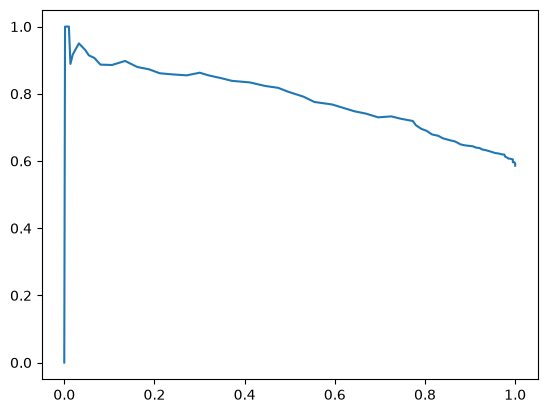

In [130]:
plt.plot(recall, precision)

In [131]:
for t in range(len(thresholds)):
    if precision[t] == recall[t]:
        print(f'threshold: {thresholds[t]}, r: {recall[t]}, p: {precision[t]}')

threshold: 0.97, r: 0.0, p: 0
threshold: 0.98, r: 0.0, p: 0
threshold: 0.99, r: 0.0, p: 0
threshold: 1.0, r: 0.0, p: 0


In [132]:
diff = []
for t in range(len(thresholds)):
    if (precision[t] != 0.0) or (recall[t] != 0.0):
        diff.append(precision[t] - recall[t])
diff = np.array(diff)
diff = np.abs(diff)
diff = diff[diff != 0.0]
minn = diff.min()

In [133]:
diff = []
for t in range(len(thresholds)):
    if (precision[t] != 0.0) or (recall[t] != 0.0):
        diff.append(precision[t] - recall[t])
        if abs(diff[t]) == minn:
            print(thresholds[t])

0.63


In [134]:
precision

[np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.586),
 np.float64(0.5865865865865866),
 np.float64(0.5877632898696088),
 np.float64(0.591321897073663),
 np.float64(0.591321897073663),
 np.float64(0.5925176946410515),
 np.float64(0.5963302752293578),
 np.float64(0.5961145194274029),
 np.float64(0.5973360655737705),
 np.float64(0.6016511867905057),
 np.float64(0.6028955532574974),
 np.float64(0.6047717842323651),
 np.float64(0.6069182389937107),
 np.float64(0.6073684210526316),
 np.float64(0.6095238095238096),
 np.float64(0.612834

In [135]:
for i in range(len(precision)):
    precision[i] = float(precision[i])

for i in range(len(recall)):
    recall[i] = float(recall[i])

In [136]:
F1 = []
for t in range(len(thresholds)):
    f1 = (2*precision[t]*recall[t]) / (precision[t] + recall[t]) if precision[t] + recall[t] != 0 else 0
    F1.append(f1)
F1 = np.array(F1)
maxx_idx = np.argmax(F1)

In [137]:
maxx_idx

np.int64(41)

In [138]:
max_threshold = thresholds[maxx_idx]
max_threshold

np.float64(0.41000000000000003)

In [139]:
[]

[]

In [140]:
from sklearn.model_selection import KFold

In [141]:
kfold = KFold(n_splits = 5, shuffle=True, random_state=1)

In [142]:
!pip install tqdm

In [143]:
from tqdm.auto import tqdm
scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=5):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)

    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f'Std: {np.std(scores).round(3)}, mean: {np.mean(scores)}')

  0%|          | 0/5 [00:00<?, ?it/s]

Std: 0.007, mean: 0.7317269710972524


In [144]:
for C in tqdm([0.000001, 0.001, 1], total=3):

    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
        
        dv, model = train(df_train, y_train, C=C)
    
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    
    print(f'C = {C}, Std: {np.std(scores).round(3)}, mean: {np.mean(scores).round(3)}')

  0%|          | 0/3 [00:00<?, ?it/s]

C = 1e-06, Std: 0.019, mean: 0.617
C = 0.001, Std: 0.01, mean: 0.749
C = 1, Std: 0.007, mean: 0.732
